## LaDe 21: Road Class Delivery Dynamics (Flag 21)

### Dataset Overview

Constructed LaDe-style courier data on archived Shanghai WGS84 OSM roads. Task IDs, schedules, movement speeds, delivery windows, AOIs and regions are synthetic extensions, not original LaDe observations. Native fclass, oneway, bridge and tunnel attributes are copied from OSM; absence of a tag is encoded no, not independent confirmation that a structure is absent. GPS retains all road vertices; spatial spacing is at most 22 m, stationary intervals at most 55 s. Each travelling row and its road_segment_id describe the immediately preceding GPS interval; stationary rows have no road attribution. Speed is distance divided by time, excluding service/waiting. Route directness ratio means travelled distance divided by straight-line task-endpoint distance. One-way share is distance weighted (0–1), not percent. Movement phases label ordered workday route periods, not fixed clock bins. Directions are checked but OSM turn restrictions are not modeled. Tunnel coordinates are constructed map interpolation, not authentic underground GPS fixes. All times are local Shanghai time. Pending tasks intentionally have no completion time or arrival leg; other task completions coincide with stationary GPS fixes. Service visits are recorded intervals at roadside task sites, not official AOI boundaries. Repositioning and return legs remain visible but are excluded where an insight concerns task-to-task legs.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Identify how road classes shape the courier's movement and delivery activity.

Role: Last-mile logistics analyst


Category: road_class_delivery_dynamics


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What CSV-derived evidence supports insight 1?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

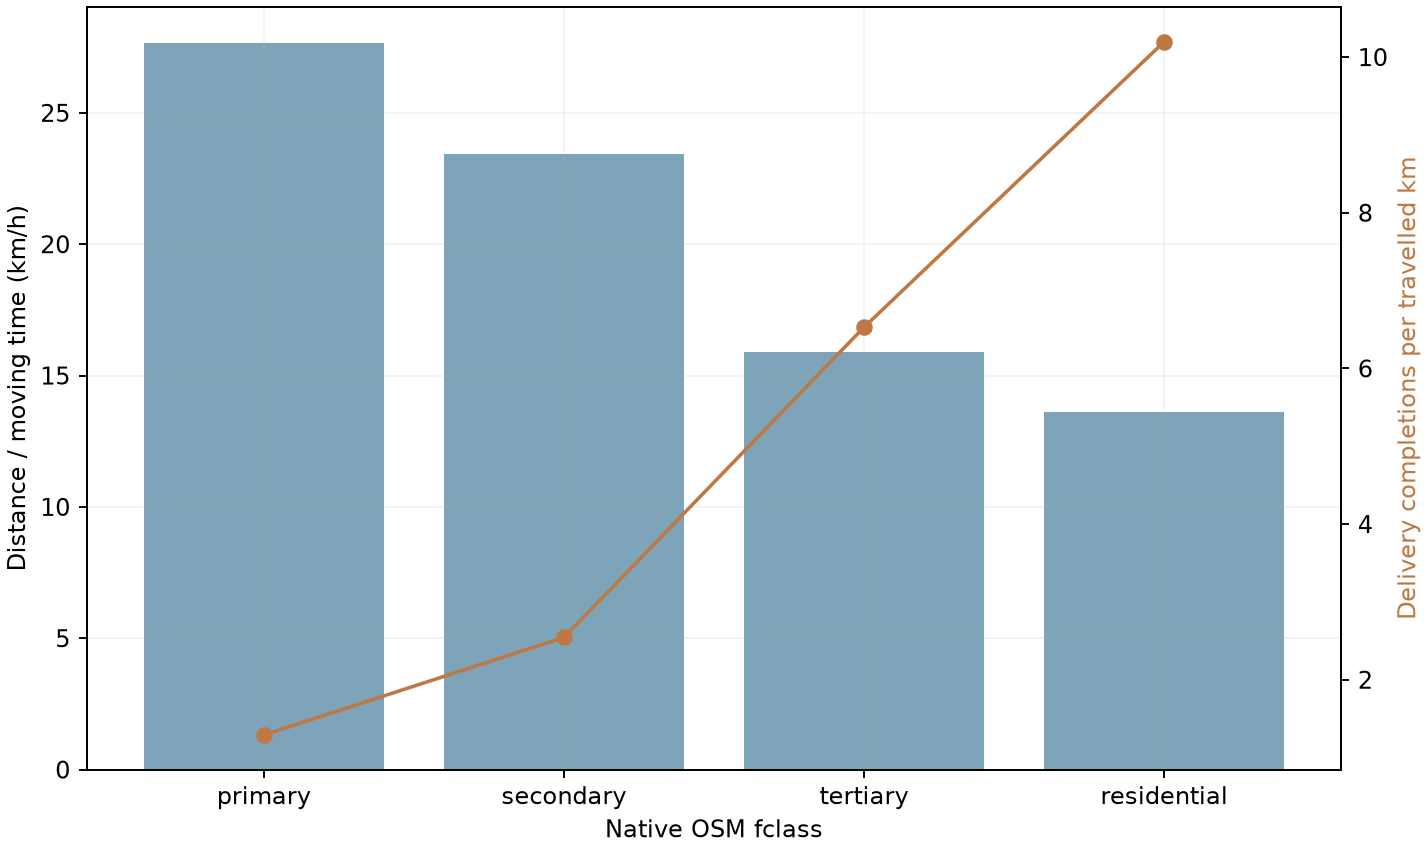

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            q.boxplot(column="route_directness_ratio", by="period", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title="Later task routes are more direct",
            )
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "days_with_fastest_delivery_leg_early": int(
                    q.loc[q.groupby("service_date").mean_speed_kmh.idxmax()]
                    .period.eq("early")
                    .sum()
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            q.boxplot(column="completion_hour", by="regular_aoi", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Regular AOI",
                ylabel="Completion hour (Shanghai local time)",
                title="Regular wide-window deliveries are deferred",
            )
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(21, 1, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_1",
  "insight_type": "group_comparison",
  "insight": "Movement on primary roads is generally faster and contains fewer delivery completions than movement on residential roads, with secondary and tertiary roads showing intermediate patterns.",
  "insight_value": {
    "road_class_summary": {
      "primary": {
        "step_distance_km": 38.74580955311451,
        "step_duration_s": 5045.6405998010005,
        "movement_speed_kmh": 27.64463929450574,
        "completions": 50,
        "completions_per_km": 1.2904621319489462
      },
      "secondary": {
        "step_distance_km": 37.73862192066369,
        "step_duration_s": 5798.319335171,
        "movement_speed_kmh": 23.43076175372163,
        "completions": 96,
        "completions_per_km": 2.5438130783317088
      },
      "tertiary": {
        "step_distance_km": 24.656980700815513,
        "step_duration_s": 5588.740395847,
        "movement_speed_kmh": 15.882850917336816,
        "completions": 161,
        "completions_per_km": 6.529591029556795
      },
      "residential": {
        "step_distance_km": 27.164184579968754,
        "step_duration_s": 7192.588756805,
        "movement_speed_kmh": 13.596087277388984,
        "completions": 277,
        "completions_per_km": 10.197250691790087
      }
    }
  },
  "question": "What CSV-derived evidence supports insight 1?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 21 insight 1",
    "file": "visualizations/insight_1.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            q.boxplot(column='route_directness_ratio', by='period', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Delivery route phase', ylabel='Travelled / straight-line distance', title='Later task routes are more direct')\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'days_with_fastest_delivery_leg_early': int(q.loc[q.groupby('service_date').mean_speed_kmh.idxmax()].period.eq('early').sum())}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            q.boxplot(column='completion_hour', by='regular_aoi', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Regular AOI', ylabel='Completion hour (Shanghai local time)', title='Regular wide-window deliveries are deferred')\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict()}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(21, 1, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "fclass",
    "gps_time",
    "gps_position",
    "completion_time",
    "task_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 2**: What CSV-derived evidence supports insight 2?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

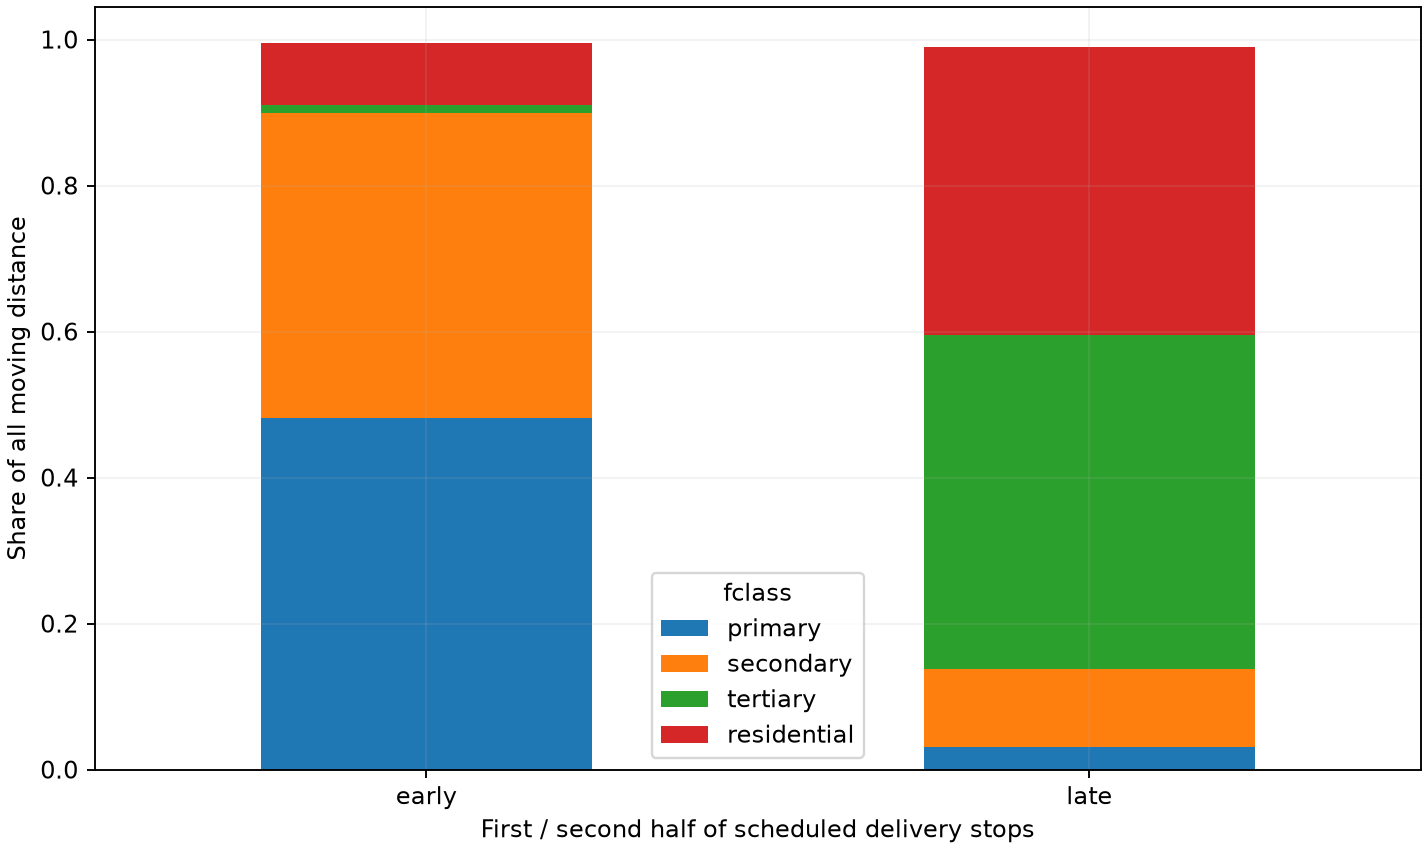

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            q.boxplot(column="route_directness_ratio", by="period", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title="Later task routes are more direct",
            )
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "days_with_fastest_delivery_leg_early": int(
                    q.loc[q.groupby("service_date").mean_speed_kmh.idxmax()]
                    .period.eq("early")
                    .sum()
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            q.boxplot(column="completion_hour", by="regular_aoi", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Regular AOI",
                ylabel="Completion hour (Shanghai local time)",
                title="Regular wide-window deliveries are deferred",
            )
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(21, 2, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_2",
  "insight_type": "temporal_dynamics",
  "insight": "Earlier route periods contain more movement on primary and secondary roads, while tertiary and residential roads become more prominent during later delivery-intensive periods.",
  "insight_value": {
    "distance_shares": {
      "early": {
        "primary": 0.4818662434176687,
        "residential": 0.0849745084860167,
        "secondary": 0.4181379109720063,
        "secondary_link": 0.0,
        "service": 0.005274713912787541,
        "tertiary": 0.009746623211520792,
        "tertiary_link": 0.0
      },
      "late": {
        "primary": 0.03146426922753251,
        "residential": 0.39489559654225675,
        "secondary": 0.10614436080228891,
        "secondary_link": 0.0001509630053279448,
        "service": 0.008627525392494326,
        "tertiary": 0.45780668740134234,
        "tertiary_link": 0.0009105976287572295
      }
    },
    "completion_counts": {
      "late": 438,
      "early": 146
    }
  },
  "question": "What CSV-derived evidence supports insight 2?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 21 insight 2",
    "file": "visualizations/insight_2.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            q.boxplot(column='route_directness_ratio', by='period', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Delivery route phase', ylabel='Travelled / straight-line distance', title='Later task routes are more direct')\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'days_with_fastest_delivery_leg_early': int(q.loc[q.groupby('service_date').mean_speed_kmh.idxmax()].period.eq('early').sum())}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            q.boxplot(column='completion_hour', by='regular_aoi', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Regular AOI', ylabel='Completion hour (Shanghai local time)', title='Regular wide-window deliveries are deferred')\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict()}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(21, 2, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "fclass",
    "gps_time",
    "completion_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 3**: What CSV-derived evidence supports insight 3?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

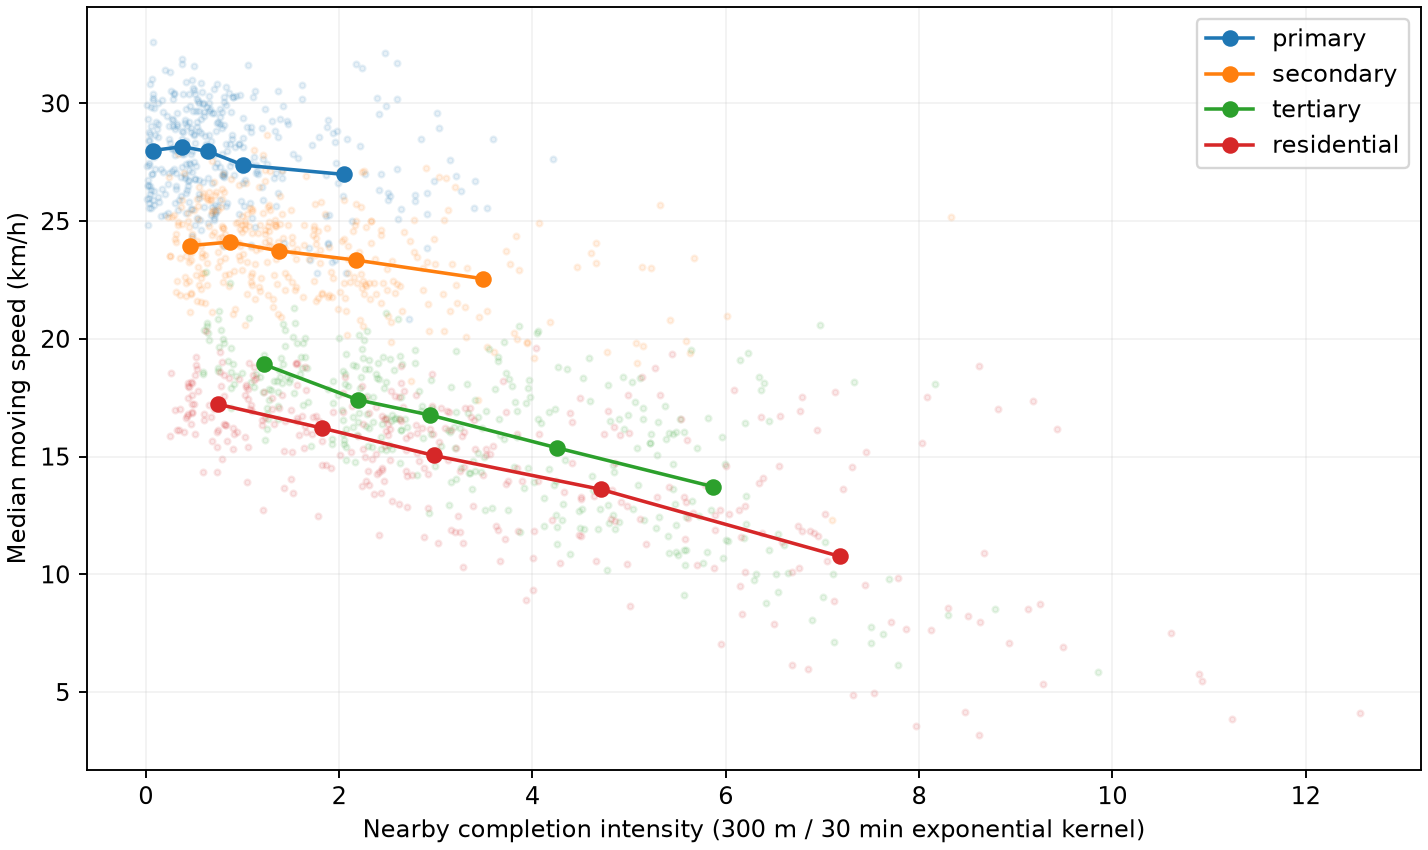

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            q.boxplot(column="route_directness_ratio", by="period", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title="Later task routes are more direct",
            )
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "days_with_fastest_delivery_leg_early": int(
                    q.loc[q.groupby("service_date").mean_speed_kmh.idxmax()]
                    .period.eq("early")
                    .sum()
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            q.boxplot(column="completion_hour", by="regular_aoi", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Regular AOI",
                ylabel="Completion hour (Shanghai local time)",
                title="Regular wide-window deliveries are deferred",
            )
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(21, 3, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_3",
  "insight_type": "factor_relationship",
  "insight": "Within the same fclass, movement speed decreases as nearby delivery activity becomes denser, with the strongest changes appearing on tertiary and residential roads.",
  "insight_value": {
    "within_class_evidence": {
      "primary": {
        "points": 2938,
        "spearman": -0.18818064305708856,
        "low_to_high_activity_speed_drop_kmh": 1.0154493163151272,
        "quintile_medians": {
          "nearby_activity": [
            0.07000884972871158,
            0.37509037173507737,
            0.6444225021753915,
            1.0077475939228593,
            2.0512694717078666
          ],
          "speed_kmh": [
            27.996636598244173,
            28.15913804032181,
            27.957855384625077,
            27.37661698221027,
            26.981187281929046
          ]
        }
      },
      "secondary": {
        "points": 2855,
        "spearman": -0.2820579195268705,
        "low_to_high_activity_speed_drop_kmh": 1.4069586555059388,
        "quintile_medians": {
          "nearby_activity": [
            0.457863954450011,
            0.870837193669007,
            1.373179532455673,
            2.1707310865839515,
            3.4876083851612596
          ],
          "speed_kmh": [
            23.958976854902843,
            24.11074178460788,
            23.739921146081684,
            23.34539950545501,
            22.552018199396905
          ]
        }
      },
      "tertiary": {
        "points": 1998,
        "spearman": -0.6396676521000074,
        "low_to_high_activity_speed_drop_kmh": 5.1925890448133,
        "quintile_medians": {
          "nearby_activity": [
            1.2178845100215896,
            2.1940546063736446,
            2.9452435269818795,
            4.255368626443791,
            5.866902467928263
          ],
          "speed_kmh": [
            18.916954886165215,
            17.40947923563568,
            16.759312616823216,
            15.37011805477653,
            13.724365841351915
          ]
        }
      },
      "residential": {
        "points": 2125,
        "spearman": -0.6183156094588609,
        "low_to_high_activity_speed_drop_kmh": 6.458264792145597,
        "quintile_medians": {
          "nearby_activity": [
            0.7515977528801265,
            1.827044431445672,
            2.980479666070908,
            4.708057560725137,
            7.18301658308327
          ],
          "speed_kmh": [
            17.218400777527886,
            16.207135470726765,
            15.047711384417353,
            13.607899902356294,
            10.76013598538229
          ]
        }
      }
    }
  },
  "question": "What CSV-derived evidence supports insight 3?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 21 insight 3",
    "file": "visualizations/insight_3.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            q.boxplot(column='route_directness_ratio', by='period', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Delivery route phase', ylabel='Travelled / straight-line distance', title='Later task routes are more direct')\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'days_with_fastest_delivery_leg_early': int(q.loc[q.groupby('service_date').mean_speed_kmh.idxmax()].period.eq('early').sum())}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            q.boxplot(column='completion_hour', by='regular_aoi', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Regular AOI', ylabel='Completion hour (Shanghai local time)', title='Regular wide-window deliveries are deferred')\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict()}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(21, 3, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "fclass",
    "gps_time",
    "gps_position",
    "completion_time",
    "task_position",
    "task_id",
    "courier_id"
  ]
}

### Summary of Findings (Flag 21)

Movement on primary roads is generally faster and contains fewer delivery completions than movement on residential roads, with secondary and tertiary roads showing intermediate patterns. Earlier route periods contain more movement on primary and secondary roads, while tertiary and residential roads become more prominent during later delivery-intensive periods. Within the same fclass, movement speed decreases as nearby delivery activity becomes denser, with the strongest changes appearing on tertiary and residential roads.